# Convergence-rate plots

Choose `CASE` in the first code cell, then run both code cells from top to bottom.
Each RMSE vector is labelled with its paper panel and quantity. Only curves shown in that panel are retained.
Natural logarithms are used for the budgets and RMSEs. The default is Figure EC.6(b).
Set `SAVE_FIGURE = True` to save a separate image under `results/generated_rates/`.

The original paper figures, including Figure EC.4(b), are in `results/figures/`.
Dependencies: matplotlib, SciPy and seaborn.


In [1]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
from scipy.stats import linregress
import seaborn as sns

CASE = "queue"  # portfolio, nonconvex, correlated_exp, correlated_normal, queue_regen, queue
SAVE_FIGURE = False

n_portfolio = [10000, 23000, 44000, 73000, 100000]  # Figure 1(b): simulation budgets
theta_portfolio = [0.037713, 0.0258760179037849, 0.020829216, 0.018350077, 0.017868906]  # Figure 1(b): portfolio, theta RMSE
cv_portfolio = [0.217977, 0.0929977913239949, 0.077745086, 0.074868074, 0.065590696]  # Figure 1(b): portfolio, CVaR pseudo RMSE
gradient_portfolio = [0.516381, 0.390621211984335, 0.334927706, 0.265295847, 0.241041876]  # Figure 1(b): portfolio, CVaR-gradient pseudo RMSE

n_nonconvex = [1000, 4500, 10000, 45000, 100000, 450000, 1000000]  # Figure EC.1(b): simulation budgets
cv_nonconvex = [11.02428256, 1.107420572, 1.184653412, 1.124722483, 0.378861652, 0.040599778, 0.031622]  # Figure EC.1(b): nonconvex, CVaR pseudo RMSE
gradient_nonconvex = [1.072043569, 0.545921696, 0.190598206, 0.130409863, 0.110312881, 0.103402117, 0.090559]  # Figure EC.1(b): nonconvex, CVaR-gradient pseudo RMSE

n_correlated_exp = [1000, 4500, 10000, 45000, 100000, 450000, 1000000]  # Figure EC.3(a): simulation budgets
theta_correlated_exp = [0.999946306, 0.258985564, 0.053821407, 0.023843649, 0.015356491, 0.006471017, 0.005000654]  # Figure EC.3(a): correlated_exp, theta RMSE

n_correlated_normal = [1000, 4500, 10000, 45000, 100000, 450000, 1000000]  # Figure EC.3(b): simulation budgets
theta_correlated_normal = [1, 0.200721406, 0.068601958, 0.021084447, 0.012199858, 0.005944527, 0.003481481]  # Figure EC.3(b): correlated_normal, theta RMSE

n_queue_regen = [1000, 2300, 5000, 10000, 23000, 25000]  # Figure EC.5(b): simulation budgets
theta_queue_regen = [6.53814938, 4.048554969, 1.946924759, 0.800873382, 0.277858945, 0.257393716]  # Figure EC.5(b): queue_regen, theta RMSE

n_queue = [1000, 2300, 5000, 10000, 23000, 25000]  # Figure EC.6(b): simulation budgets
theta_queue = [7.03651052, 4.731100324, 2.556517174, 1.187282089, 0.372413143, 0.332453817]  # Figure EC.6(b): queue, theta RMSE

CASES = {
    "portfolio": {"figure": "Figure 1(b)", "filename": "SA_jinrong_rate.png", "n": n_portfolio, "series": {'theta': theta_portfolio, 'cv': cv_portfolio, 'gradient': gradient_portfolio}},
    "nonconvex": {"figure": "Figure EC.1(b)", "filename": "SA_nonconvex_rate.png", "n": n_nonconvex, "series": {'cv': cv_nonconvex, 'gradient': gradient_nonconvex}},
    "correlated_exp": {"figure": "Figure EC.3(a)", "filename": "SA_correlated_rate_exp.png", "n": n_correlated_exp, "series": {'theta': theta_correlated_exp}},
    "correlated_normal": {"figure": "Figure EC.3(b)", "filename": "SA_correlated_rate_normal.png", "n": n_correlated_normal, "series": {'theta': theta_correlated_normal}},
    "queue_regen": {"figure": "Figure EC.5(b)", "filename": "SA_queue_correlated_rate.png", "n": n_queue_regen, "series": {'theta': theta_queue_regen}},
    "queue": {"figure": "Figure EC.6(b)", "filename": "SA_queue_rate.png", "n": n_queue, "series": {'theta': theta_queue}},
}


queue: Figure EC.6(b)
  theta: slope=-0.98415330, intercept=9.03995545


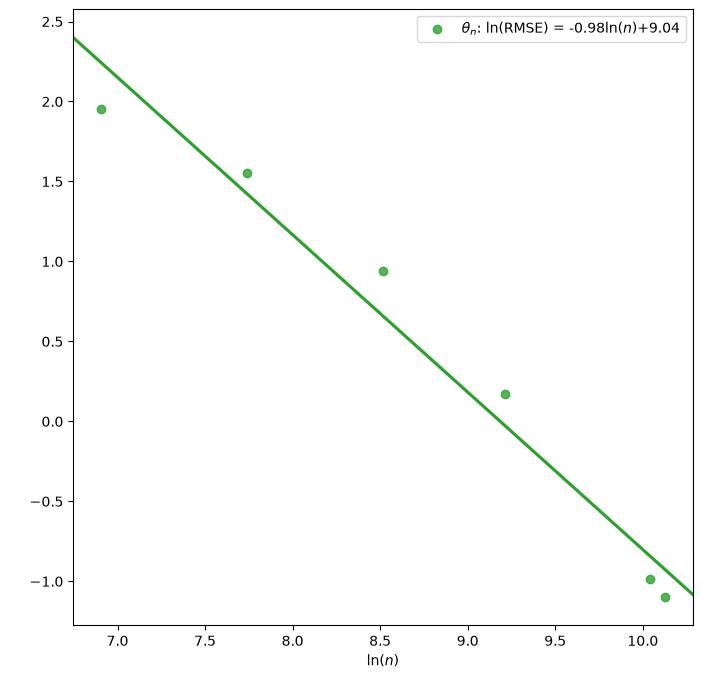

In [2]:
selected = CASES[CASE]
logn = [math.log(n) for n in selected["n"]]
styles = {
    "theta": (r"$\theta_n$", "RMSE", "tab:green"),
    "cv": (r"$c_n$", "pseudo RMSE", "#FF8C00"),
    "gradient": (r"$G_{c,n}$", "pseudo RMSE", "tab:purple"),
}

fig, ax = plt.subplots(figsize=(8, 8))
print(f"{CASE}: {selected['figure']}")
for quantity, rmse in selected["series"].items():
    if len(rmse) != len(logn) or any(value <= 0 for value in rmse):
        raise ValueError(f"{CASE}/{quantity}: budgets and positive RMSE values must match.")
    log_rmse = [math.log(value) for value in rmse]
    slope, intercept, *_ = linregress(logn, log_rmse)
    name, error_name, color = styles[quantity]
    label = f"{name}: ln({error_name}) = {slope:.2f}ln($n$){intercept:+.2f}"
    sns.regplot(x=logn, y=log_rmse, ci=None, label=label, color=color, truncate=False, ax=ax)
    print(f"  {quantity}: slope={slope:.8f}, intercept={intercept:.8f}")

ax.legend()
ax.set_ylabel(" ")
ax.set_xlabel(r"ln($n$)")
if SAVE_FIGURE:
    here = Path.cwd()
    if (here / "results").is_dir():
        root = here
    elif (here.parent / "results").is_dir():
        root = here.parent
    else:
        raise FileNotFoundError("Run this notebook from the repository root or scripts directory.")
    output_dir = root / "results" / "generated_rates"
    output_dir.mkdir(parents=True, exist_ok=True)
    output_path = output_dir / selected["filename"]
    fig.savefig(output_path, dpi=150, bbox_inches="tight")
    print(f"Saved: {output_path}")
plt.show()


Copyright (c) 2026 Qixin Wang, Hao Cao, and Jian-Qiang Hu

SPDX-License-Identifier: MIT

See the repository [LICENSE](../LICENSE).
